In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

In [2]:
plt.rcParams['legend.markerscale'] = 1.5     # the relative size of legend markers vs. original
plt.rcParams['legend.handletextpad'] = 0.5
plt.rcParams['legend.labelspacing'] = 0.4    # the vertical space between the legend entries in fraction of fontsize
plt.rcParams['legend.borderpad'] = 0.5       # border whitespace in fontsize units
plt.rcParams['font.size'] = 12
plt.rcParams['font.serif'] = 'Times New Roman'
plt.rcParams['axes.labelsize'] = 22
plt.rcParams['axes.titlesize'] = 24
plt.rcParams['figure.figsize'] = (10, 6)

plt.rc('xtick', labelsize=18)
plt.rc('ytick', labelsize=18)
plt.rc('legend', fontsize=22)

# 1. Общий случай

## Статистическая гипотеза и статистический критерий

**Статистическая гипотеза** $-$ любое предположение о распределении и свойствах случайной величины.

**Cтатистический критерий** $-$ математическое правило, позволяющее по реализациям выборок отвергнуть или не отвергнуть нулевую гипотезу с заданным уровнем значимости.

Дана выборка $X_1, \ldots, X_n \sim F$.

Хотим проверить простую гипотезу $H_0$ против сложной альтернативы $H_1$.

Пусть можно задать функцию $t (X^n)$, обладающую свойствами:

1. если $H_0$ верна, то $t (X^n) \Rightarrow G$, где $G$ — непрерывное распределение;
2. если $H_0$ неверна, то $|t (X^n)| \overset{P}{\to} \infty$ при $n\to \infty$.


Для СВ $Y\sim G$ определим постоянную $C$ из равенства $\alpha = \mathbb{P}(|Y| \geq C)$.

Тогда критерий:
\begin{equation*}
    \delta (X^n) = 
    \left\{
    \begin{aligned}
        &H_0,\ если\ t(X^n) < C,\\
        &H_1,\ если\ t(X^n) \geq C
    \end{aligned}
    \right.
\end{equation*}

In [3]:
true_p = 0.6
size = 100

x = np.random.binomial(1, p=true_p, size=size)

def t(x):
    return np.abs(np.mean(x) - 1/2) * size ** 0.5
t(x)

np.float64(1.3)

## Уровень значимости, мощность, критическая область

**Уровень значимости** $-$ вероятность отклонить нулевую гипотезу при условии её истинности.

**Статистическая мощность** $-$ вероятность отклонения основной гипотезы в случае, когда альтернативная гипотеза верна.

**Критическая область** $-$ область выборочного пространства, при попадании в которую нулевая гипотеза отклоняется.

## Этапы проверки статистических гипотез


1. Выдвижение основной гипотезы $H_0$ и альтернативной гипотезы $H_1$.
2. Выбор уровня значимости $\alpha$, на котором будет сделан вывод о справедливости гипотезы. Он равен вероятности допустить ошибку первого рода.
3. Расчет статистики критерия такой, что она зависит от выборки, и по её значению можно сделать вывод об истинности нулевой гипотезы.
4. Построение критической области.
5. По попаданию или непопаданию значения статистики в критическую область делается вывод об истинности выдвинутой гипотезы на выбранном уровне значимости.


# 2. Тест Стьюдента

## Гипотеза о равенстве средних

Нулевая и альтернативная гипотезы:

- $H_0:$ средние двух групп равны, $m_1 = m_2$

- $H_1:$ средние двух групп неравны, $m_1 \ne m_2$

## Распределение Стьюдента

Для выборки $X_1, X_2, \ldots, X_n \sim N(\mu, \sigma^2)$ из нормального распределения с неизвестной дисперсией мы можем определить статистику: 

$$ 
    \left<X\right> = \frac1n \sum_{i=1}^n X_i,\quad
    S^2 = \frac1{n-1} \sum_{i=1}^n (X_i - \left<X\right>)^2, \quad
    t = \frac{\left<X\right> - \mu}{\dfrac{S}{\sqrt{n}}}.    
$$

При этом случайная величина $t$ имеет распределение Стьюдента с (n-1) степенью свободы. При росте n распределение стремится к нормальному, но в практически значимых случаях конечных выборок у этого распределения значительно более тяжелые хвосты, что повышает шансы заметных отклонений.

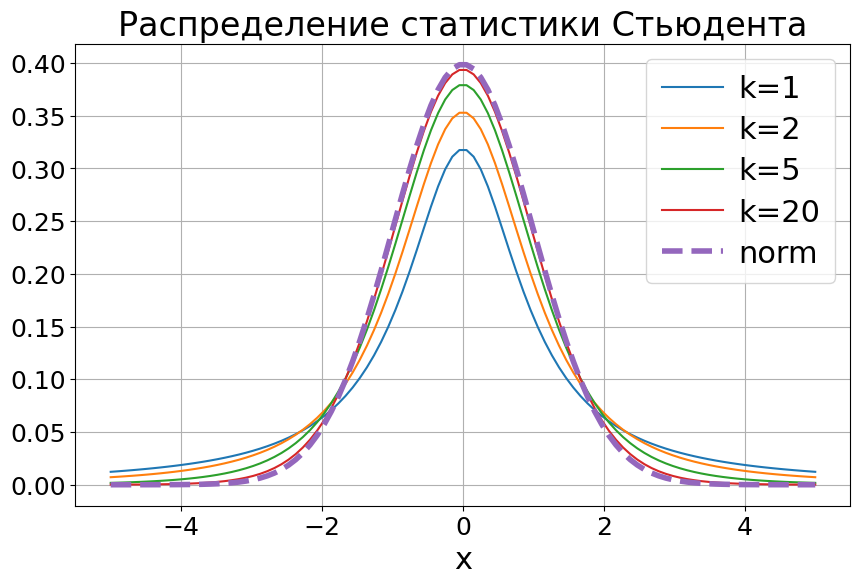

In [4]:
X = np.linspace(-5, 5, 100)
list_k = [1, 2, 5, 20]
for k in list_k:
    Y = stats.t.pdf(X, k)
    plt.plot(X, Y, label=f'k={k}')

Y = stats.norm.pdf(X, 0, 1)
plt.plot(X, Y, '--', label='norm', linewidth=4)

plt.legend()
plt.title('Распределение статистики Стьюдента')
plt.xlabel('x')
plt.grid()
plt.show()

## Тест Стьюдента

Есть две выборки: $X_1,\ldots,X_{n_1}\sim N(\mu_1, \sigma_1)$ и $Y_1,\ldots,Y_{n_2}\sim N(\mu_2, \sigma_2)$.
    
Гипотезы: $H_0: \mathbb{E}{X} = \mathbb{E}{Y}$ и $H_1: \mathbb{E}{X} \neq \mathbb{E}{Y}$.

Статистика теста:
$$t(X^n, Y^n) = \dfrac{\overline{Y} - \overline{X}}{\sqrt{\dfrac{S^2_X}{n_1} + \dfrac{S^2_Y}{n_2}}} \approx St(\nu), \qquad \nu = \frac{\left(\dfrac{S^2_X}{n_1} + \dfrac{S^2_Y}{n_2}\right)^2}{\dfrac{S_X^4}{n_1^2 (n_1 - 1)} + \dfrac{S_Y^4}{n_2^2 (n_2 - 1)}}$$

Самостоятельно реализуем вычисление t-статистики: 

In [5]:
def get_student_parameter(data_one: np.array, data_two: np.array) -> float:
    """Вычисляет параметр функции распределения Стьюдента."""
    len_one, len_two = len(data_one), len(data_one)
    std_one, std_two = np.std(data_one), np.std(data_two)
    k = (
        ((std_one ** 2) / len_one + (std_two ** 2) / len_two) ** 2
        / (
            (std_one ** 4) / ((len_one ** 2) * (len_one - 1))
            + (std_two ** 4) / ((len_two ** 2) * (len_two - 1))
        )
    )
    return k


def get_ttest_statistic(data_one: np.array, data_two: np.array) -> float:
    """Считает статистику Стьюдента"""
    len_one, len_two = len(data_one), len(data_two)
    mean_one, mean_two = np.mean(data_one), np.mean(data_two)
    std_one, std_two = np.std(data_one, ddof=1), np.std(data_two, ddof=1)
    t = (mean_two - mean_one) / np.sqrt((std_two**2 / len_two) + (std_one**2 / len_one))
    return t

Сверим результаты с готовой реализацией теста

In [6]:
sample_size = 100
alpha = 0.05

np.random.seed(44)
data_control = np.random.normal(1, 1, sample_size)
data_pilot = np.random.normal(1.2, 1, sample_size)

k = get_student_parameter(data_control, data_pilot)
print(f'student_parameter = {k}')

critical_region_bounds = stats.t.ppf([alpha/2, 1 - alpha/2], df=k)
print(f'critical_region_bounds = {critical_region_bounds}')

ttest_statistic = get_ttest_statistic(data_control, data_pilot)
print(f'ttest_statistic = {ttest_statistic}')

pvalue = stats.t.cdf(-np.abs(ttest_statistic), df=k) * 2
print(f'pvalue = {pvalue}')

# сверим с готовой реализацией
ttest_statistic_real, pvalue_real = stats.ttest_ind(data_pilot, data_control)
print(f'stats.ttest_ind = {stats.ttest_ind(data_pilot, data_control)}')
assert np.isclose(ttest_statistic_real, ttest_statistic, 1e-9), 'Статистика посчитана неверно'

student_parameter = 196.53643393447297
critical_region_bounds = [-1.97210778  1.97210778]
ttest_statistic = 1.8203056424009751
pvalue = 0.07023355774410753
stats.ttest_ind = TtestResult(statistic=np.float64(1.8203056424009751), pvalue=np.float64(0.07022230781028713), df=np.float64(198.0))


Построим критические области критерия

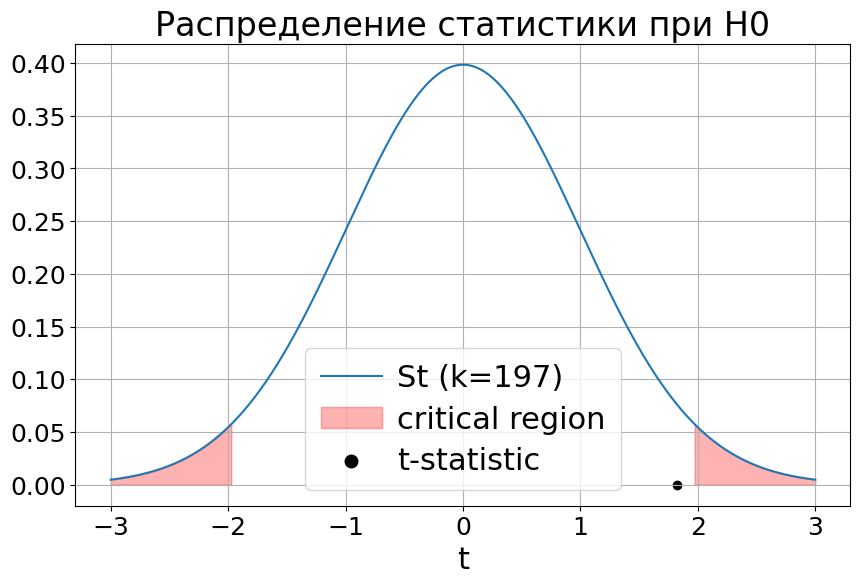

In [7]:
X = np.linspace(-3, 3, 1000)
Y = stats.t.pdf(X, k)

plt.plot(X, Y, label=f'St (k={k:0.0f})')

critical_mask_list = [X < critical_region_bounds[0], X > critical_region_bounds[1]]
for idx, mask in enumerate(critical_mask_list):
    X_ = X[mask]
    Y_upper = Y[mask]
    Y_down = np.zeros(len(Y_upper))
    plt.fill_between(
        X_, Y_down, Y_upper,
        color='r', alpha=0.3,
        label='critical region' if idx==0 else ''
    )

plt.scatter([ttest_statistic], [0], color='k', label='t-statistic')

plt.title('Распределение статистики при H0')
plt.xlabel('t')
plt.legend()
plt.grid()
plt.show()

# 3. Двусторонний и односторонние критерии

Критическая область зависит от альтернативы

#### Двусторонний критерий

- $H_1$: $\theta \ne \theta_0$

#### Правосторонняя гипотеза

- $H_1$: $\theta > \theta_0$

#### Левосторонняя гипотеза

- $H_1$: $\theta < \theta_0$

Для гипотезы о равенстве средних $\theta = t$ и $\theta_0 = 0$.



Построим критическую область одностороннего критерия.

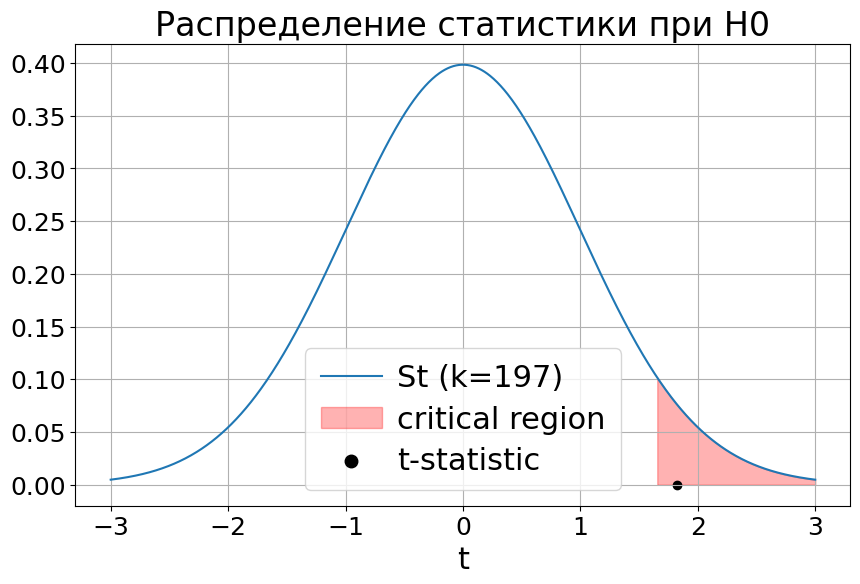

In [8]:
sample_size = 100
alpha = 0.05

k = get_student_parameter(data_control, data_pilot)
critical_region_bound = stats.t.ppf([1 - alpha], df=k)


X = np.linspace(-3, 3, 1000)
Y = stats.t.pdf(X, k)

plt.plot(X, Y, label=f'St (k={k:0.0f})')

mask = X > critical_region_bound
X_ = X[mask]
Y_upper = Y[mask]
Y_down = np.zeros(len(Y_upper))
plt.fill_between(
    X_, Y_down, Y_upper,
    color='r', alpha=0.3,
    label='critical region'
)

plt.scatter([ttest_statistic], [0], color='k', label='t-statistic')

plt.title('Распределение статистики при H0')
plt.xlabel('t')
plt.legend()
plt.grid()
plt.show()

Односторонние критерии обычно применяют в случаях, когда нас не интересует отклонение в одну из сторон.

В нашем курсе по умолчанию будем рассматривать только двусторонние критерии.

# 4. p-value

p-value – вероятность наблюдать полученное или более экстремальное значение статистики при условии, что нулевая гипотеза верна. 

$$
p{-}value = \mathbb{P}(T > t | H_0)
$$

Статистический критерий можно записать как

$$
p{-}value < \alpha \iff отвергнуть~гипотезу
$$

In [9]:
x = np.random.normal(0, 1, 100)
y = np.random.normal(0.4, 1, 100)
stats.ttest_ind(x, y)

TtestResult(statistic=np.float64(-5.100310939750893), pvalue=np.float64(7.909852153789629e-07), df=np.float64(198.0))

# 5. Данные пиццерии

Посчитаем p-value для эксперимента с изменением дизайна сайта.

In [10]:
import os
from datetime import datetime, timedelta
import pandas as pd

URL_BASE = 'https://raw.githubusercontent.com/ab-courses/simulator-ab-datasets/main/2022-04-01/'

def read_database(file_name):
    return pd.read_csv(os.path.join(URL_BASE, file_name))

In [11]:
df_sales = read_database('2022-04-01T12_df_sales.csv')
df_sales['date'] = pd.to_datetime(df_sales['date'])
df_users = read_database('experiment_users.csv')

df_sales - информация о покупках, одна строка - один заказ. Атрибуты:
- sale_id - идентификатор покупки;
- date - дата покупки;
- count_pizza - количество пицц в заказе;
- count_drink - количество напитков в заказе;
- price - стоимость заказа;
- user_id - идентификатор пользователя;

df_users - список пользователей эксперимента с разбивкой на группы

In [12]:
df_users.head()

,user_id,pilot
0,0ffc65,0
1,b962b9,0
2,7ea63f,0
3,7f9a61,0
4,459e55,0


In [13]:
# количество пользователей в группах
df_users['pilot'].value_counts()

pilot
0    11769
1    11564
Name: count, dtype: int64

In [14]:
# считаем значения метрики
begin_date = datetime(2022, 3, 23)
end_date = datetime(2022, 3, 30)
df_metrics = (
    df_sales
    [(df_sales['date'] >= begin_date) & (df_sales['date'] < end_date)]
    .groupby('user_id')[['price']].sum()
    .reset_index()  
)

In [15]:
df_metrics.head()

,user_id,price
0,0000d4,720
1,0000de,660
2,0000e4,840
3,0001e2,2430
4,0001ff,720


In [16]:
df = pd.merge(df_users, df_metrics, on='user_id', how='left').fillna(0)

In [17]:
df.head()

,user_id,pilot,price
0,0ffc65,0,0.0
1,b962b9,0,840.0
2,7ea63f,0,0.0
3,7f9a61,0,0.0
4,459e55,0,0.0


In [18]:
data_control = df[df['pilot'] == 0]['price']
data_pilot = df[df['pilot'] == 1]['price']
stats.ttest_ind(data_control, data_pilot)

TtestResult(statistic=np.float64(-7.800743549967138), pvalue=np.float64(6.4112917182248024e-15), df=np.float64(23331.0))

Получили близкое к нулю p-value, как и на платформе.

**Вывод:** 
- На уровне значимости 0.05 гипотеза о равенстве средних отклоняется
- Изменение статистически значимо

ДЗ
Возьмите те же группы, что и в эксперименте с изменением дизайна сайта, и проверьте значимость отличий средней выручки с пользователя на неделе перед экспериментом (c 2022.03.16 по 2022.03.23).

Для решения используйте данные из файлов 2022-04-01T12_df_sales.csv и experiment_users.csv.

In [19]:
# считаем значения метрики
begin_date_pred = datetime(2022, 3, 16)
end_date_pred = datetime(2022, 3, 23)
df_metrics_pred = (
    df_sales
    [(df_sales['date'] >= begin_date_pred) & (df_sales['date'] < end_date_pred)]
    .groupby('user_id')[['price']].sum()
    .reset_index()  
)
df_metrics_pred

,user_id,price
0,000096,720
1,00092c,780
2,000bb2,720
3,000ea9,1560
4,000ec6,690
...,...,...
24595,fff3ec,660
24596,fff6b5,3480
24597,fff8bf,2880
24598,fff98d,3480


In [21]:
df_pred = pd.merge(df_users, df_metrics_pred, on='user_id', how='left').fillna(0)

data_control_pred = df_pred[df_pred['pilot'] == 0]['price']

data_pilot_pred = df_pred[df_pred['pilot'] == 1]['price']

stats.ttest_ind(data_control_pred, data_pilot_pred)

TtestResult(statistic=np.float64(-1.2837567415000515), pvalue=np.float64(0.1992398330642495), df=np.float64(23331.0))